# Fiche 5 — Une image, un masque : des tableaux de nombres

| | |
|---|---|
| 🎯 **Objectif** | Manipuler une photo et son masque comme des tableaux NumPy, et les afficher côte à côte avec un code couleur fixe |
| ⏱️ **Durée** | 45 min |
| 🧰 **Prérequis** | Fiche 3 |
| 🔗 **Dans le projet** | Étape 5 (visualiser : image originale vs image segmentée) |

> **L'idée clé.** Pour Python, une photo est un tableau **hauteur × largeur × 3 couleurs**, et un masque un tableau **hauteur × largeur** où chaque nombre est une classe. Tout le reste, ce sont des opérations sur ces tableaux.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from segvet import io, viz
from segvet.labels import CLASSES, FRENCH

viz.apply_style()
image_path, mask_path = io.load_pairs()[0]
photo = np.array(Image.open(image_path).convert("RGB"))
masque = io.read_mask(mask_path)
print("photo :", photo.shape, photo.dtype, "| masque :", masque.shape, masque.dtype)

photo : (600, 400, 3) uint8 | masque : (600, 400) uint8


## 1. Lire les formes

`(600, 400, 3)` : 600 lignes (la hauteur), 400 colonnes (la largeur), 3 valeurs par pixel (rouge, vert, bleu, de 0
à 255). Le masque `(600, 400)` n'a qu'une valeur par pixel : l'identifiant de sa classe.

⚠️ Pillow dit l'inverse : `Image.open(...).size` renvoie **(largeur, hauteur)**. Les deux conventions cohabitent dans
le projet ; d'où les `size[::-1]` qu'on croise parfois.

In [2]:
print("Pillow .size  (largeur, hauteur) :", Image.open(image_path).size)
print("NumPy .shape (hauteur, largeur) :", masque.shape)

valeurs, nombres = np.unique(masque, return_counts=True)
for v, n in zip(valeurs, nombres):
    print(f"{v:>3} = {FRENCH[CLASSES[v]]:<18} {n:>7} pixels")

Pillow .size  (largeur, hauteur) : (400, 600)
NumPy .shape (hauteur, largeur) : (600, 400)
  0 = Fond                189803 pixels
  2 = Cheveux               3286 pixels
  4 = Haut                 32277 pixels
  6 = Pantalon              8161 pixels
  9 = Chaussure gauche      1464 pixels
 10 = Chaussure droite      1644 pixels
 11 = Visage                1956 pixels
 12 = Jambe gauche           255 pixels
 13 = Jambe droite           236 pixels
 15 = Bras droit             140 pixels
 16 = Sac                    778 pixels


## 2. Du nombre à la couleur

Afficher le masque brut donne une image presque noire (des nombres de 0 à 17 sur une échelle qui va jusqu'à 255).
On associe donc une couleur à chaque classe, **toujours la même** dans tout le projet : le haut est bleu sur toutes
les figures, sinon on ne peut pas comparer deux images. Le tableau `viz.CLASS_COLORS` (18 lignes × 3 couleurs) sert
de table de correspondance : `CLASS_COLORS[masque]` remplace chaque identifiant par sa couleur, en une opération.

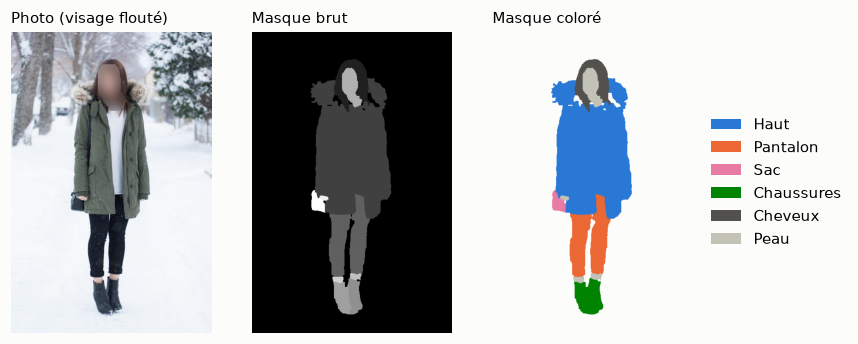

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(8, 4.2))
axes[0].imshow(viz.blur_faces(photo, masque))
axes[0].set_title("Photo (visage flouté)", fontsize=10, fontweight="normal")
axes[1].imshow(masque, cmap="gray")
axes[1].set_title("Masque brut", fontsize=10, fontweight="normal")
axes[2].imshow(viz.CLASS_COLORS[masque])
axes[2].set_title("Masque coloré", fontsize=10, fontweight="normal")
for ax in axes:
    ax.axis("off")
axes[2].legend(handles=viz.legend_handles(masque), loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

## 3. Des masques de l'API à une seule carte

L'API ne renvoie pas une carte toute faite, mais **un masque noir et blanc par classe** (fiche 3). Pour obtenir une
carte comme l'annotation, on part d'une carte remplie de 0 (le fond), puis on « peint » chaque masque avec
l'identifiant de sa classe. Essai sur deux classes de la réponse conservée :

In [4]:
import base64
import io as octets_io
import json

from segvet import cache
from segvet.labels import CLASS_TO_ID

reponse = json.loads((cache.PROCESSED_DIR / "exemple_reponse_api.json").read_text())["response"]
largeur, hauteur = Image.open(image_path).size
carte = np.zeros((hauteur, largeur), dtype=np.uint8)          # tout en fond (0) au départ
for element in reponse:
    if element["label"] not in ("Upper-clothes", "Pants"):     # deux classes pour l'exemple
        continue
    m = Image.open(octets_io.BytesIO(base64.b64decode(element["mask"]))).resize((largeur, hauteur), Image.NEAREST)
    carte[np.array(m) > 0] = CLASS_TO_ID[element["label"]]
print("Valeurs de la carte :", np.unique(carte).tolist(), "→", [FRENCH[CLASSES[v]] for v in np.unique(carte)])

Valeurs de la carte : [0, 4, 6] → ['Fond', 'Haut', 'Pantalon']


Le masque renvoyé a la taille de l'image **envoyée** (512 px de haut ici) : on le ramène d'abord à la taille de la
photo. Avec toutes les classes, on obtient la carte complète ; le package du projet le fait dans `combine_masks`.

Le visage est flouté à partir de l'annotation elle-même (la classe « visage ») : ce sont des photos de vraies
personnes, et une figure publiée n'a pas besoin de les rendre reconnaissables.

## ⚠️ Piège : agrandir un masque comme une photo

Pour comparer deux masques, il faut qu'ils aient la même taille. Une photo s'agrandit avec une interpolation
**lisse** (*bilinéaire*) : elle invente des couleurs intermédiaires, ce qui est joli. Sur un masque, une valeur
intermédiaire entre 4 (haut) et 6 (pantalon), c'est… 5, une **jupe** qui n'existe pas.

In [5]:
petit = Image.fromarray(masque).resize((100, 150), Image.NEAREST)
retour_lisse = np.array(petit.resize((400, 600), Image.BILINEAR))
retour_net = np.array(petit.resize((400, 600), Image.NEAREST))

avant = set(np.unique(masque))
for nom, resultat in [("bilinéaire", retour_lisse), ("plus proche voisin", retour_net)]:
    fantomes = sorted(set(np.unique(resultat)) - avant)
    print(f"{nom:<19}: classes inventées {[FRENCH[CLASSES[c]] for c in fantomes]}")

bilinéaire         : classes inventées ['Chapeau', 'Lunettes de soleil', 'Jupe', 'Robe', 'Ceinture', 'Bras gauche']
plus proche voisin : classes inventées []


**Lecture.** L'interpolation bilinéaire fait apparaître des classes absentes de l'image d'origine, le long des
frontières. Le remède : redimensionner les masques **au plus proche voisin** (`Image.NEAREST`), qui recopie la
valeur du pixel le plus proche sans rien inventer. C'est ce que fait `decode_base64_mask` dans le projet.

### ✍️ À toi de jouer

Écris une fonction `part_vetements(masque)` qui renvoie la part des pixels de **la personne** (tout sauf le fond) occupée par des vêtements et accessoires (les classes de `segvet.labels.CLOTHING`). Applique-la au masque ci-dessus.

In [6]:
# Ta réponse ici

<details>
<summary><b>💡 Voir une solution</b> (après avoir cherché !)</summary>

```python
from segvet.labels import CLASS_TO_ID, CLOTHING

def part_vetements(masque):
    ids_vetements = [CLASS_TO_ID[c] for c in CLOTHING]
    personne = masque != CLASS_TO_ID["Background"]
    vetements = np.isin(masque, ids_vetements)
    return vetements.sum() / personne.sum()

print(f"{part_vetements(masque):.0%}")
```

**Pourquoi ?** `np.isin` teste l'appartenance à une liste pour tous les pixels d'un coup ; diviser par les pixels de la personne (et non de l'image) évite que le fond, qui occupe près de 80 % de l'image, écrase le chiffre.

</details>

## ✅ À retenir

1. Photo = tableau (hauteur, largeur, 3) ; masque = tableau (hauteur, largeur) d'identifiants de classes.
2. Pillow donne `size` = (largeur, hauteur), NumPy donne `shape` = (hauteur, largeur) : attention à l'ordre.
3. Une table de couleurs fixe (`CLASS_COLORS[masque]`) : la même classe a la même couleur sur toutes les figures.
4. Un masque se redimensionne **au plus proche voisin**, jamais en bilinéaire.
5. Photos de personnes réelles : on floute les visages dans tout ce qui est publié.